# Introduction à l'IA Générative et au RAG
*Cours Pratique & Exercices Pas à Pas*
Bienvenue dans votre premier TP d'intelligence artificielle !

*L'objectif* d'aujourd'hui est de comprendre comment fonctionnent les modèles de langage et de construire votre premier assistant intelligent capable de lire des documents d'entreprise sans inventer de fausses informations.

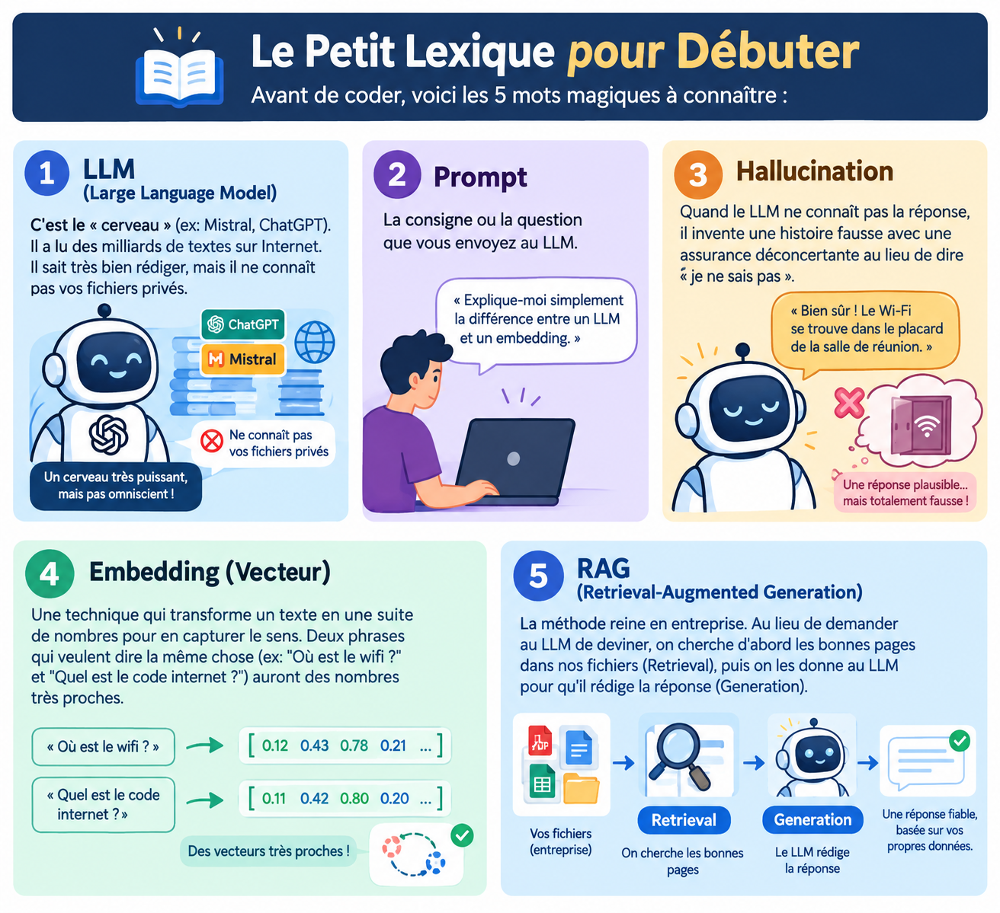

### Installation

Taper cette commande dans votre terminal

`uv add python-dotenv langchain-text-splitters langchain-community chromadb langchain-huggingface langchain-mistralai sentence-transformers pypdf`

In [1]:
import os
from dotenv import load_dotenv

# Les outils LangChain pour manipuler le texte et les modèles
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_community.vectorstores import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_mistralai import ChatMistralAI
from langchain_core.messages import HumanMessage, AIMessage
import time


# Chargement de la clé d'API (MISTRAL_API_KEY) depuis le fichier .env
print("Environnement prêt !")

/home/diabate/Bureau/formation_python/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_1241019/4222204286.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFDirectoryLoader


Environnement prêt !


# 📚 Partie 1 : Déchiffrer les Outils de LangChain & Mistral

Avant d'écrire du code, décortiquons les objets que nous allons manipuler.

### 1. ChatMistralAI (Le Cerveau)
* **C'est quoi ?** C'est une classe Python qui sert de pont entre notre code et les serveurs de Mistral AI.
* **Ses paramètres principaux :**
  * `model="ministral-8b-2512"` : Précise quel modèle ("cerveau") on veut utiliser chez Mistral.
  * `temperature=0` : Règle le niveau de créativité.
    * `0` = Le modèle est ultra-rigide, factuel et précis (idéal pour un assistant d'hôtel).
    * `1` = Le modèle devient très créatif et inventif (idéal pour écrire des histoires).
* **Ce qu'il crée :** Un objet `llm` prêt à recevoir des instructions.

### 2. HumanMessage et AIMessage (La Structure de Discussion)
Un LLM ne lit pas le texte comme un simple fil d'exécution. Il a besoin de savoir **qui parle**.
* **HumanMessage :** Un objet qui emballe le texte envoyé par l'utilisateur humain.
  * *Paramètre :* `content="Ta question ici"`
* **AIMessage :** Un objet renvoyé par le modèle, contenant la réponse générée par l'IA.

### 3. .invoke() (Le Bouton d'Action)
* **C'est quoi ?** C'est la méthode (la fonction) qui envoie nos messages à l'IA à travers Internet et attend la réponse.
* **Ce qu'il prend en paramètre :** Une liste de messages, par exemple : `[HumanMessage(content="Bonjour")]`.
* **Ce qu'il renvoie :** Un objet de type `AIMessage`.
* **Pourquoi .content à la fin ?** L'objet `AIMessage` contient la réponse mais aussi plein de métadonnées (nombre de mots utilisés, modèle exact, etc.). En faisant `reponse.content`, on n'extrait **que la phrase de réponse**.

*Á TOI DE JOUER :*

1. Crée une instance du modèle ChatMistralAI.

2. Envoie une question via HumanMessage.

3. Observe la réponse.

`https://admin.mistral.ai/organization/api-keys` Lien pour créer api_key

In [2]:
load_dotenv()

print("Clé trouvée :", bool(os.getenv("MISTRAL_API_KEY")))

Clé trouvée : True


In [3]:
time.sleep(5)

llm = ChatMistralAI(
    model="ministral-8b-2512",
    temperature=0
)

response = llm.invoke("Bonjour, réponds simplement : ça va bien ?")

print(response.content)

Oui, merci ! 😊 Et toi ?


In [4]:
response = llm.invoke("Je me nomme Diabaté Youssouf")

print(response.content)

Bonjour Youssouf Diabaté ! 😊

C’est un nom qui évoque une riche culture, notamment liée à la tradition mandingue et à la musique (comme le célèbre griot **Djeli Youssouf Cissé** ou les familles de griots du Mali). Si vous êtes lié à cette lignée ou simplement inspiré par ce nom, je serais ravi d’échanger avec vous sur :

- **La culture mandingue** (griots, traditions, histoire)
- **La musique** (kora, balafon, djembé, etc.)
- **L’histoire du Mali ou de l’Afrique de l’Ouest**
- **Votre parcours** (si vous souhaitez partager une passion ou un projet)

Dites-moi, qu’est-ce qui vous inspire ou vous passionne en lien avec ce nom ou votre identité ? 🌍🎶

*(Petit détail : "Diabaté" peut aussi désigner un "griot" ou un "conteur" en bambara, ce qui est magnifique !)*

À vous de jouer ! 😊


In [5]:
response = llm.invoke("comment je m'appelle ?")

print(response.content)

Je ne connais pas ton nom ! 😊

Si tu veux me le dire, je peux t'aider avec n'importe quoi d'autre (réponses, conseils, idées, etc.). À toi de jouer ! 🚀

*(Ou peut-être que tu cherches à savoir comment on t'appelle dans un contexte particulier ?)*


Waoo! Et pourtant on a bien dit le nom. 

*C'est le problème de mémoire qu'on verra à la suite comment gérer ?*

On peut poser ce genre de question, il répond correctement comme fait chatgpt.

In [6]:
time.sleep(5)

# 2. Préparation de la question
question = "Quels sont les tarifs de la chambre Classique à l'Hôtel Le Belvédère ?"

# 3. Envoi au LLM
# ### COMPLÈTE LE CODE CI-DESSOUS ###
message = HumanMessage(content=question)
reponse = llm.invoke([message])

print("Réponse du LLM :")
print(reponse.content)

Réponse du LLM :
Pour connaître les **tarifs actuels de la chambre Classique à l'Hôtel Le Belvédère**, voici les options possibles :

1. **Site officiel de l'hôtel** :
   - Consultez directement leur [site web](https://www.hotel-le-belvedere.com) (ou leur page Booking/Google) pour vérifier les prix en temps réel, car ils peuvent varier selon la saison, les promotions ou la disponibilité.
   - Exemple de tarifs (à confirmer) :
     - **Chambre Classique** (standard) : entre **120 € et 200 €/nuit** (hors saison) et **200 € à 350 €/nuit** (haute saison, été, événements).
     - **Petit-déjeuner** : souvent inclus ou en supplément (~15-25 €/pers.).

2. **Plateformes de réservation** :
   - Sur [Booking.com](https://www.booking.com), [Expedia](https://www.expedia.fr) ou [Trivago](https://www.trivago.fr), filtrez par "Hôtel Le Belvédère" et comparez les offres.

3. **Contact direct** :
   - Appelez l'hôtel au **+33 (0)X XXX XXX XXX** (remplacez par leur numéro réel) ou écrivez-leur via leur 

## Cas échéant

In [7]:
question = "Combien coûte la nuitée en chambre Classique à l'Hôtel Le Belvédère ?"
message_humain = HumanMessage(content=question)

# ÉTAPE 3 : Á TOI DE JOUER !
# Envoie 'message_humain' au modèle via 'llm.invoke()' (n'oublie pas les crochets [] autour du message)
# Affiche uniquement le texte de la réponse avec .content

### COMPLÈTE LE CODE CI-DESSOUS ###
reponse = llm.invoke([message_humain])

print("--- Réponse du LLM simple ---")
print(reponse.content)

--- Réponse du LLM simple ---
Je n'ai pas d'informations en temps réel sur les tarifs actuels de l'**Hôtel Le Belvédère** (ou d'autres établissements).

Pour connaître le prix exact d'une **nuitée en chambre Classique**, je vous recommande de :
1. **Consulter directement leur site officiel** : [www.hotelbelvedere.com](https://www.hotelbelvedere.com) (ou leur page Facebook/Instagram si disponible).
2. **Appeler l'hôtel** pour vérifier les tarifs et les éventuelles promotions.
3. **Utiliser des comparateurs** comme Booking, Expedia ou Agoda.

Les prix varient selon la saison, les événements locaux et les options choisies (petit-déjeuner, vue, etc.).

Si vous avez besoin d'aide pour trouver l'hôtel (adresse, localisation), je peux aussi vous aider ! 😊


**Le constat des limites :**
Le modèle n'a jamais eu accès aux fichiers internes de l'hôtel. Deux cas de figure se produisent : soit il avoue ne pas savoir, soit il invente un prix ou des détails plausibles mais faux. C'est ce qu'on appelle une hallucination. Un LLM seul ne suffit pas pour traiter des données d'entreprise.

## 📚 Partie 2 : Charger et Découper la Documentation (PDF & Chunking)
Pour résoudre ce problème, il faut donner accès aux vrais documents de l'hôtel. Mais un document complet est trop long : nous allons le découper en petits morceaux appelés chunks.

1. *`PyPDFDirectoryLoader`*
À quoi ça sert ? Il lit automatiquement tous les fichiers `.pdf` stockés dans un dossier local (par exemple le dossier "data").

Sa méthode .`load()` : Renvoie une liste d'objets Document représentant chaque page PDF.

2. *`RecursiveCharacterTextSplitter`*
À quoi ça sert ? Il découpe le texte long en petits morceaux (chunks).

Ses paramètres :

*`chunk_size=300`*: La taille maximale de chaque morceau (300 caractères).

*`chunk_overlap=30`* : Le nombre de caractères partagés entre deux morceaux consécutifs (pour éviter de couper une phrase en plein milieu).

Sa méthode *`.load_and_split(...)`* : Prend la liste des pages lues et retourne la liste des morceaux découpés.

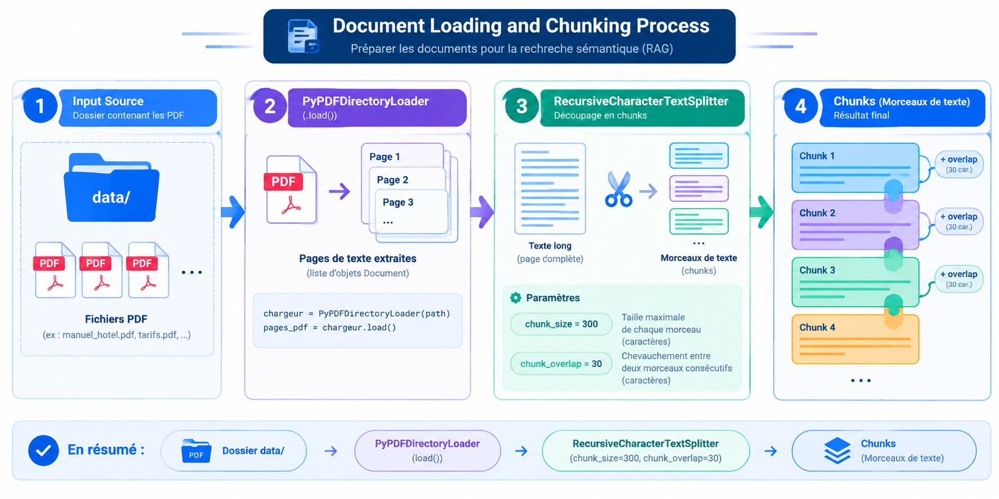

## Exercice 2 : 
Charger et Découper les Fichiers PDF

In [8]:
# ÉTAPE 1 : Chargement des PDF depuis le dossier "data"
path = "./data"
chargeur = PyPDFDirectoryLoader(path)


# ÉTAPE 2 : Configuration du découpeur de texte
decoupeur = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=30
)


# ÉTAPE 3 : Chargement + découpage des PDF
morceaux_texte = chargeur.load_and_split(decoupeur)


print(f"Nombre total de morceaux (chunks) : {len(morceaux_texte)}")
print("\n--- Exemple du premier morceau ---")
print(morceaux_texte[0].page_content)

Nombre total de morceaux (chunks) : 47

--- Exemple du premier morceau ---
Familles et enfants
Les lits bébé et les chaises hautes sont fournis gratuitement sur demande, dans la limite des stocks
disponibles. Un kids club est organisé le mercredi et le week-end en juillet et août, de 10h à 12h, pour les


## 📚 Partie 3 : Moteur de Recherche Sémantique (Embeddings & ChromaDB)
Maintenant que nos documents sont découpés, nous devons pouvoir retrouver instantanément le bon morceau quand un client pose une question.

1. **HuggingFaceEmbeddings**
À quoi ça sert ? C'est un modèle qui transforme du texte en coordonnées mathématiques (un vecteur).

Le principe : Deux phrases qui expriment la même idée (ex: "Chiens acceptés ?" et "Animaux de compagnie autorisés") auront des coordonnées mathématiques très proches.

*Le paramètre* : `model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"` spécifie le modèle d'embeddings multilingue (adapté au français).

2. **Chroma**
À quoi ça sert ? C'est une base de données vectorielle. Elle stocke les morceaux de texte ainsi que leurs coordonnées mathématiques.

La méthode `Chroma.from_documents(...)` : Prend les morceaux de texte (documents) et le modèle d'embeddings (embedding) pour construire la base.

3. **La méthode** `.as_retriever()`
À quoi ça sert ? Transforme la base Chroma en un moteur de recherche.

Le paramètre : `search_kwargs={"k": 2}` indique au moteur de ne sélectionner que les 2 morceaux les plus pertinents lors d'une recherche.

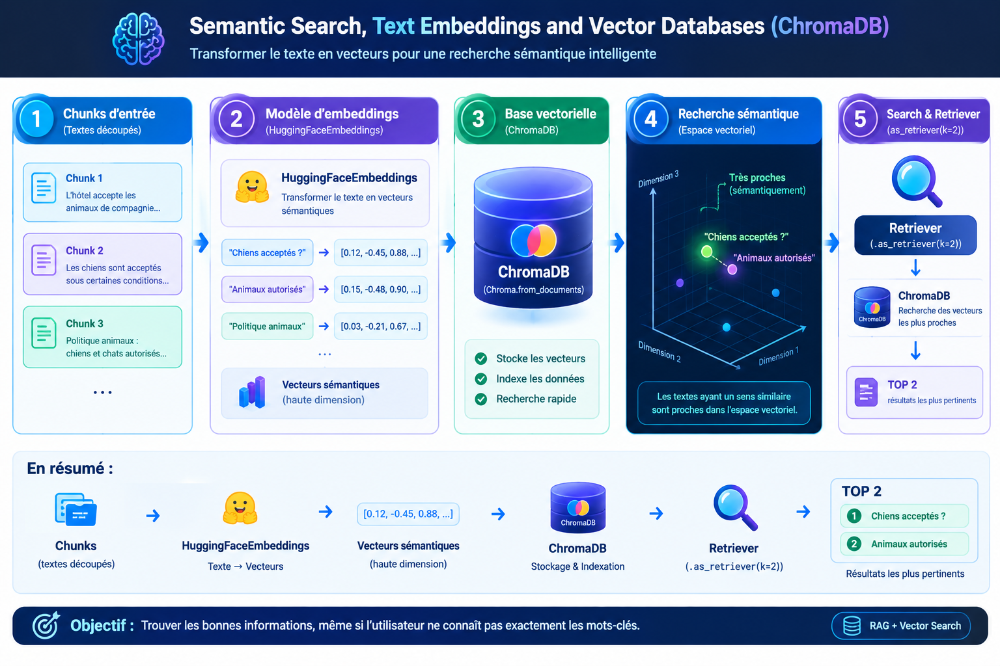

## Exercice 3 : Créer la Base Vectorielle et Moteur de Recherche

In [9]:
# ÉTAPE 1 : Initialisation du générateur d'embeddings
generateur_embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

# ÉTAPE 2 : Création de la base vectorielle Chroma
base_vectorielle = Chroma.from_documents(
    documents=morceaux_texte,
    embedding=generateur_embeddings
)

# ÉTAPE 3 : Transformation de la base en moteur de recherche (retriever)
moteur_recherche = base_vectorielle.as_retriever(type="similarity", search_kwargs={"k": 2})

# ÉTAPE 4 : Á TOI DE JOUER !
# Lance une recherche sémantique avec la méthode .invoke() du 'moteur_recherche'
question_client = "À quelle heure démarre le check-in ?"

### COMPLÈTE LE CODE CI-DESSOUS ###
morceaux_trouves = moteur_recherche.invoke(question_client)

print(f"Nombre de morceaux trouvés : {len(morceaux_trouves)}\n")
for i, doc in enumerate(morceaux_trouves):
    print(f"--- Morceau {i+1} ---")
    print(doc.page_content)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3464.68it/s]


Nombre de morceaux trouvés : 2

--- Morceau 1 ---
Horaires de la réception
La réception de l'Hôtel Le Belvédère est ouverte tous les jours de 7h à 22h. En dehors de ces horaires, un
numéro d'astreinte est affiché à l'entrée pour toute urgence. Le check-in démarre à 15h et le check-out se fait
--- Morceau 2 ---
avant 11h. Un départ tardif jusqu'à 13h peut être accordé gratuitement selon la disponibilité des chambres, il
suffit de le demander la veille à la réception. Une arrivée tardive après 22h doit être annoncée à l'avance par
téléphone ou email pour que le personnel de nuit prépare la remise des clés.


In [10]:
morceaux_trouves

[Document(metadata={'producer': 'PyPDF', 'page': 0, 'page_label': '1', 'source': 'data/informations_pratiques.pdf', 'creator': 'PyPDF', 'title': 'Informations Pratiques', 'total_pages': 4, 'author': 'Hôtel Le Belvédère', 'creationdate': '2026-07-23T12:06:10+00:00'}, page_content="Horaires de la réception\nLa réception de l'Hôtel Le Belvédère est ouverte tous les jours de 7h à 22h. En dehors de ces horaires, un\nnuméro d'astreinte est affiché à l'entrée pour toute urgence. Le check-in démarre à 15h et le check-out se fait"),
 Document(metadata={'creationdate': '2026-07-23T12:06:10+00:00', 'page_label': '1', 'title': 'Informations Pratiques', 'page': 0, 'producer': 'PyPDF', 'total_pages': 4, 'creator': 'PyPDF', 'author': 'Hôtel Le Belvédère', 'source': 'data/informations_pratiques.pdf'}, page_content="avant 11h. Un départ tardif jusqu'à 13h peut être accordé gratuitement selon la disponibilité des chambres, il\nsuffit de le demander la veille à la réception. Une arrivée tardive après 22h

## Partie 4 : Assembler le Pipeline RAG Complet

Le RAG (Retrieval-Augmented Generation) combine tout ce que nous venons de construire :

Retrieval (Recherche) : Le moteur_recherche extrait les 2 morceaux les plus proches de la question du client.

Augmentation : On injecte ces morceaux dans une consigne (prompt) avec des instructions strictes.

Generation (Génération) : On transmet le prompt au LLM Mistral pour qu'il rédige une réponse accurate.

In [11]:
def repondre_client(question_du_client: str) -> str:
    # 1. Recherche des morceaux de texte pertinents dans ChromaDB
    docs = moteur_recherche.invoke(question_du_client)
    
    # 2. Fusion des textes trouvés dans une variable de contexte
    contexte_extrait = "\n\n".join([d.page_content for d in docs])
    
    # 3. Rédaction du prompt d'instruction
    prompt_rag = f"""Tu es l'assistant officiel de l'Hôtel Le Belvédère.
Réponds à la question du client en t'appuyant STRICTEMENT sur le contexte ci-dessous.
Si l'information ne se trouve pas dans le contexte, réponds exactement : "Je ne sais pas, veuillez contacter la réception."

Contexte officiel :
{contexte_extrait}

Question du client : {question_du_client}
"""

    # 4. Á TOI DE JOUER !
    # Crée un objet HumanMessage avec 'prompt_rag' en contenu
    # Passe-le à 'llm.invoke()' et retourne le texte (.content)

    ### COMPLÈTE LE CODE CI-DESSOUS ###
    msg = HumanMessage(content=prompt_rag)
    reponse_finale = llm.invoke([msg])
    
    return reponse_finale.content


In [12]:
# --- TESTS DU SYSTEME RAG ---
print("=== TEST 1 : Question avec information présente ===")
print(repondre_client("Combien coûte la nuitée en chambre Classique ?"))

print("\n=== TEST 2 : Question absente de la documentation ===")
print(repondre_client("Est-il possible de payer en Bitcoins ?"))

=== TEST 1 : Question avec information présente ===


La nuitée en **Chambre Classique** coûte entre **210 et 260 euros** selon la période.

=== TEST 2 : Question absente de la documentation ===
Je ne sais pas, veuillez contacter la réception.


## Partie 6 : La Mémoire et le RAG Conversationnel

Un LLM par défaut est stateless (sans état) : il oublie tout d'un appel à l'autre. 

Pour lui donner de la mémoire, nous devons conserver une liste de messages (HumanMessage et AIMessage) et la lui ré-envoyer à chaque tour de conversation.

### Exercice 6 : Créer une fonction RAG avec Mémoire

Nous allons combiner notre moteur de recherche `moteur_recherche` (ChromaDB) avec une liste `historique_chat` pour permettre au client de poser des questions de suivi (ex: "Et est-ce qu'elle a un balcon ?").

In [13]:
# 1. Création de la mémoire globale
historique_chat = []

def repondre_rag_conversationnel(question_client: str) -> str:
    # Étape 1 : Recherche RAG dans la base ChromaDB
    docs = moteur_recherche.invoke(question_client)
    contexte_extrait = "\n\n".join([d.page_content for d in docs])
    
    # Étape 2 : Préparation du message contenant le contexte documentaire
    prompt_enrichi = f"""[DONNÉES DE LA DOCUMENTATION]   

                         {contexte_extrait}
                         
                        [QUESTION DU CLIENT]
                        {question_client}
                        """

    # Étape 3 : On ajoute la question enrichie à notre mémoire
    historique_chat.append(HumanMessage(content=prompt_enrichi))
    
    # Étape 4 : Á TOI DE JOUER !
    # 1. Envoie toute la liste 'historique_chat' au modèle via 'llm.invoke()'
    # 2. Ajoute la réponse de l'IA dans 'historique_chat' sous forme d'AIMessage
    # 3. Retourne uniquement le texte de la réponse (.content)

    ### COMPLÈTE LE CODE CI-DESSOUS ###
    reponse = llm.invoke(historique_chat)
    historique_chat.append(AIMessage(content=reponse.content))
    
    return reponse.content


# --- TESTS DU RAG CONVERSATIONNEL ---
print("=== ÉCHANGE 1 ===")
print("Client : Quels sont les équipements de la Suite Panoramic ?")
print("IA     :", repondre_rag_conversationnel("Quels sont les équipements de la Suite Panoramic ?"))

print("\n=== ÉCHANGE 2 (Question de suivi utilisant la mémoire) ===")
print("Client : Est-ce qu'elle possède un jacuzzi privatif ?")
print("IA     :", repondre_rag_conversationnel("Est-ce qu'elle possède un jacuzzi privatif ?"))

=== ÉCHANGE 1 ===
Client : Quels sont les équipements de la Suite Panoramic ?


IA     : D'après les **données de la documentation interne** de l'**Hôtel Le Belvédère** (Annecy), la **Suite Panoramic** (bien que non explicitement décrite dans les extraits fournis) bénéficie probablement des équipements standards mentionnés pour les chambres, avec des **améliorations spécifiques** pour une suite haut de gamme. Voici ce que l'on peut déduire ou extrapoler :

---

### **Équipements de la Suite Panoramic (estimations basées sur la documentation et standards hôteliers premium)**
1. **Connexion Internet haut débit**
   - **Fibre optique** avec un **débit de 500 Mbps** (identique aux autres chambres).
   - Assistance technique disponible à la réception en cas de problème (routeur de dépannage ou dépannage basique).

2. **Sécurité et rangement**
   - **Coffre-fort gratuit** (suffisamment grand pour un ordinateur portable, probablement plus spacieux qu'une chambre standard).

3. **Équipements supplémentaires typiques d'une suite** (non mentionnés dans la doc, mais souvent 

In [14]:
print("\n=== ÉCHANGE 3 (Question de suivi utilisant la mémoire) ===")
print("Client : Je me nomme Youssouf Diabaté")
print("IA     :", repondre_rag_conversationnel(" Je me nomme Youssouf Diabaté. Est-ce qu'elle possède un jacuzzi privatif ?"))


=== ÉCHANGE 3 (Question de suivi utilisant la mémoire) ===
Client : Je me nomme Youssouf Diabaté


IA     : **Bonjour Monsieur Diabaté,**

D’après la documentation interne de l’**Hôtel Le Belvédère**, **aucune chambre ou suite ne dispose d’un jacuzzi privatif**. Le seul jacuzzi disponible est celui du **Spa Les Thermes du Lac**, qui est un espace **partagé** (réservation obligatoire, ouvert de 10h à 19h).

---
### **Pour votre séjour :**
- Si vous souhaitez utiliser un jacuzzi, vous devrez **réserver une séance dans le spa** (sur place ou via la réception).
- Concernant les **animaux**, ils ne sont pas autorisés dans le spa ni à la piscine, mais peuvent être tolérés **en terrasse** (en laisse).

---
### **Conseil supplémentaire :**
Si vous souhaitez une **suite avec des équipements premium** (comme un jacuzzi privatif), je vous recommande de vérifier auprès de la réception ou de confirmer votre réservation en précisant vos besoins. Certains tarifs ou suites haut de gamme peuvent inclure des prestations supplémentaires non mentionnées dans la documentation standard.

N’hésitez pas à 

In [15]:
print("\n=== ÉCHANGE 4 (Question de suivi utilisant la mémoire) ===")
print("Client : Comment je m'appelle ?")
print("IA     :", repondre_rag_conversationnel(" Comment je m'appelle ?"))


=== ÉCHANGE 4 (Question de suivi utilisant la mémoire) ===
Client : Comment je m'appelle ?
IA     : **Bonjour Monsieur Diabaté,**

Vous vous appelez **Youssouf Diabaté**, comme mentionné dans votre message.

Si vous avez besoin d’aide pour autre chose (réservation, équipements de l’hôtel, etc.), n’hésitez pas à me le dire ! 😊

**Cordialement,**
[Votre service / Assistance]


L'Agent essayer de faire exactement ce qu'on lui a donné dans le système prompt mais il se rappelle du nom dans la conservation mais si on but n'est pas ça.

# Partie 7 : Vers un Vrai Agent Intelligent (LLM + Mémoire + RAG + Tools)

Un simple chatbot RAG ne fait que lire des documents. Si vous voulez créer un Vrai Agent IA, il lui faut 4 éléments indissociables :$$\text{AGENT IA} = \text{Cerveau (LLM)} + \text{Mémoire (Historique)} + \text{Connaissance (RAG)} + \text{Action (Tools)}$$

*Les 4 Briques de l'Agent :*
* Le Cerveau (ChatMistralAI) : Réfléchit, analyse l'intention du client et prend des décisions.

* La Mémoire (HumanMessage / AIMessage) : Maintient le fil de la conversation.

* La Connaissance (ChromaDB / RAG) : Récupère les infos exactes dans les fichiers PDF de l'hôtel.

* Les Outils (Tools) : Fonctions Python capables d'exécuter des calculs exacts ou des requêtes métier (ex: calculer une facture, vérifier la disponibilité d'une chambre).

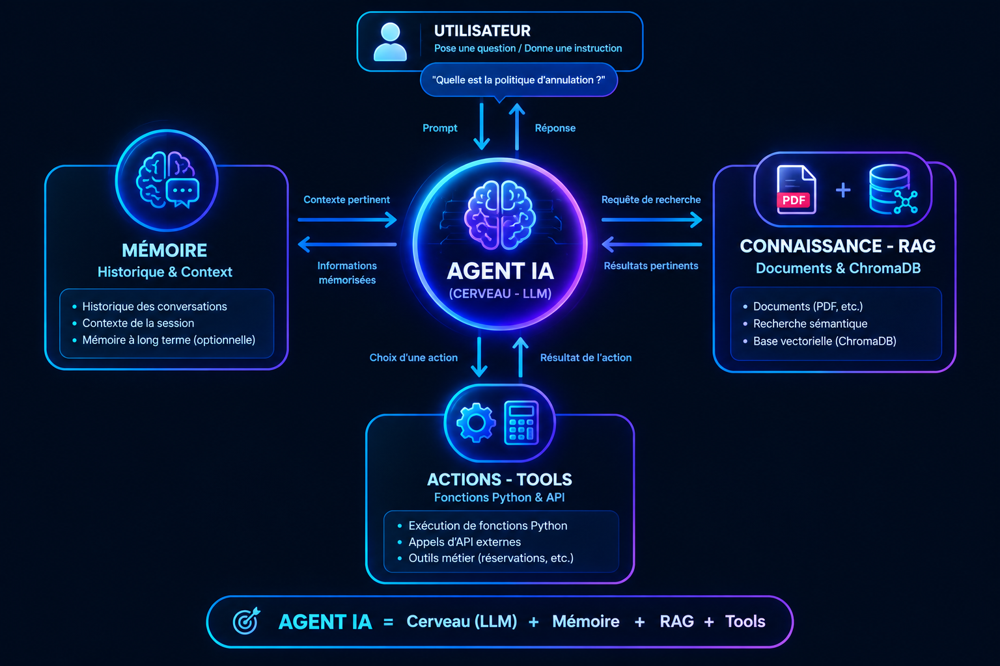

### Exercice 7 : Construction du Vrai Agent Complet

Nous allons définir des outils métier sous forme de fonctions Python, puis laisser le LLM orchestrer l'ensemble.

In [16]:
# -------------------------------------------------------------
# 1. OUTILS (TOOLS)
# -------------------------------------------------------------

def tool_calculer_facture(nb_nuits: int, prix_par_nuit: float) -> str:
    """Calcule le prix exact avec la taxe de séjour (2.50€ / nuit)."""
    taxe = 2.50 * nb_nuits
    total = (nb_nuits * prix_par_nuit) + taxe
    return f"Calcul : {nb_nuits} nuits × {prix_par_nuit}€ + {taxe}€ (taxe de séjour) = {total}€ au total."

def tool_verifier_disponibilite(type_chambre: str) -> str:
    """Vérifie le stock de chambres."""
    dispos = {"Classique": 4, "Deluxe": 1, "Suite Panoramic": 0}
    nb = dispos.get(type_chambre, 0)
    if nb > 0:
        return f"Stock : Il reste {nb} chambre(s) '{type_chambre}'."
    return f"Stock : La chambre '{type_chambre}' est complète."


# -------------------------------------------------------------
# 2. EXTRACTION DES PARAMÈTRES ET EXÉCUTION
# -------------------------------------------------------------

historique_agent = []

def agent_hotel_complet(demande_client: str) -> str:
    print(f"\n[Client] : {demande_client}")
    
    # ÉTAPE 1 : Décision de l'action
    prompt_decision = f"""Analyse la demande et réponds uniquement par un mot :
- 'RAG' : question générale sur les services ou horaires.
- 'CALCUL' : demande de prix total ou tarif de séjour.
- 'DISPO' : vérification de disponibilité.

Demande : {demande_client}
Décision :"""
    
    decision = llm.invoke([HumanMessage(content=prompt_decision)]).content.strip().upper()
    print(f"[Agent - Décision] -> {decision}")
    
    # ÉTAPE 2 : Exécution de l'outil approprié
    info_outil = ""
    
    if "CALCUL" in decision:
        # L'IA extrait d'abord le nombre de nuits et le tarif de la question du client
        prompt_extract = f"""Extrais de cette phrase le nombre de nuits et le prix sous le format NUIT,PRIX (exemple: 5,120).
Phrase : {demande_client}
Résultat :"""
        res = llm.invoke([HumanMessage(content=prompt_extract)]).content.strip()
        
        try:
            nuits, prix = map(float, res.split(","))
            info_outil = tool_calculer_facture(int(nuits), prix)
        except:
            # Valeurs par défaut si non spécifiées
            info_outil = tool_calculer_facture(1, 100.0)

    elif "DISPO" in decision:
        info_outil = tool_verifier_disponibilite("Suite Panoramic")

    elif "RAG" in decision:
        docs = moteur_recherche.invoke(demande_client)
        info_outil = "Données PDF : " + " ".join([d.page_content for d in docs])

    # ÉTAPE 3 : Synthèse courte et sans fioritures
    prompt_synthese = f"""[DONNÉE OBTENUE]
{info_outil}

[QUESTION DU CLIENT]
{demande_client}

Consignes STRICTES de réponse :
1. Sois direct et réponds en 1 à 2 phrases maximum.
2. Si un calcul ou un prix est demandé, donne le montant exact immédiatement.
3. Ne rédige PAS de salutation longue, pas de formule de politesse inutile, pas de signature.
4. N'utilise AUCUN texte entre crochets comme [Nom de l'hôtel].
"""

    # ÉTAPE 4 : Exécution et sauvegarde dans l'historique
    historique_agent.append(HumanMessage(content=prompt_synthese))
    reponse = llm.invoke(historique_agent)
    historique_agent.append(AIMessage(content=reponse.content))
    
    return reponse.content


# --- SIMULATION ---

# Test 1 : Demande de prix (Outil Calcul)
print("IA :", agent_hotel_complet("Combien me coûteront 4 nuits à 110€ la nuit ?"))

# Test 2 : Question RAG courte
print("IA :", agent_hotel_complet("À quelle heure le petit-déjeuner est-il servi ?"))

# Test 3 : Question Disponibilité
print("IA :", agent_hotel_complet("Est-ce qu'il reste une Suite Panoramic libre ?"))


[Client] : Combien me coûteront 4 nuits à 110€ la nuit ?
[Agent - Décision] -> **CALCUL**
IA : 4 nuits à 110 € la nuit coûtent **450 €** (hors frais supplémentaires éventuels).

[Client] : À quelle heure le petit-déjeuner est-il servi ?
[Agent - Décision] -> **HORAIRES**
IA : Le petit-déjeuner est servi de **7h à 10h**.

[Client] : Est-ce qu'il reste une Suite Panoramic libre ?
[Agent - Décision] -> **DISPO**
IA : Non, la **Suite Panoramic** est complète.



#  Mini-Projet Intégrateur : Industrialisation de l'Agent IA d'Hôtel

### 🎯 Objectif du Projet

Transformer le script d'Agent RAG (Mistral AI + ChromaDB) en un **produit web complet et exploitable en production**. Vous allez construire une architecture en 3 tiers :

```
┌─────────────────────────┐      REST API      ┌─────────────────────────┐
│   Frontend Streamlit    │ <────────────────> │    Backend FastAPI      │
│ (Interface Chat & Dash) │     (JSON)         │ (Agent IA + Logic)      │
└─────────────────────────┘                    └────────────┬────────────┘
                                                            │
                                            ┌───────────────┴───────────────┐
                                            ▼                               ▼
                             ┌─────────────────────────┐     ┌─────────────────────────┐
                             │  Base de données SQL    │     │ Base Vectorielle Chroma │
                             │  (Historique & Logs)    │     │    (Documents RAG)      │
                             └─────────────────────────┘     └─────────────────────────┘

```

---

## 📋 Cahier des Charges (Deliverables)

### Partie 1 : Base de Données (SQL)

Créez une base de données (SQLite ou PostgreSQL) gérant l'historique et les statistiques d'utilisation.

* **Table `conversations**` :
* `id` (INTEGER, Primary Key)
* `session_id` (VARCHAR) : Identifiant de la session utilisateur.
* `user_query` (TEXT) : Question posée par le client.
* `agent_response` (TEXT) : Réponse générée par l'agent.
* `intent_detected` (VARCHAR) : Intention détectée (`RAG`, `CALCUL`, `DISPO`, `DIRECT`).
* `created_at` (TIMESTAMP) : Date et heure de l'échange.



---

### Partie 2 : Backend API (FastAPI)

Développez une API REST robuste qui encapsule la logique de l'Agent IA.

* **`POST /api/chat`** :
* **Input** : `{"session_id": "string", "message": "string"}`
* **Traitements** :
1. Exécute la logique de l'Agent IA (Routage + RAG/Tools + Mémoire).
2. Enregistre la question, la réponse et l'intention dans la base SQL.


* **Output** : `{"response": "string", "intent": "string", "timestamp": "string"}`


* **`GET /api/history/{session_id}`** :
* Récupère l'historique complet des échanges d'une session depuis la base SQL.


* **`GET /api/analytics/summary`** :
* Retourne des agrégations SQL pour le dashboard (ex: nombre total de questions, répartition des intentions `% RAG`, `% CALCUL`, `% DISPO`).



---

### Partie 3 : Frontend (Streamlit)

Créez une interface utilisateur ergonomique comportant **2 onglets** :

#### Onglet 1 : 💬 Chatbot Client

* Interface de chat moderne avec `st.chat_input` et `st.chat_message`.
* Envoi des messages à l'API FastAPI via la bibliothèque `requests`.
* Affichage en direct du type de réponse (`[Intention : RAG]` ou `[Intention : CALCUL]`).

#### Onglet 2 : 📊 Dashboard Admin & Analyse de Données

* **KPIs clés** : Nombre total de conversations, temps de réponse moyen, taux d'appels aux outils.
* **Graphique 1** : Répartition des requêtes par intention (Camembert / Donut avec Plotly ou Altair).
* **Graphique 2** : Volume de questions par jour/heure (Histogramme).
* **Tableau interactif** : Consultation et filtrage des logs complets enregistrés en base SQL.

---

## 🛠️ Structure du Projet à Réaliser

Invitez vos étudiants à organiser leur code selon la structure suivante :

```text
mon_projet_hotel/
│
├── data/                       # Fichiers PDF de l'hôtel
│   └── brochure_hotel.pdf
│
├── backend/
│   ├── main.py                 # Application FastAPI & Routes
│   ├── agent.py                # Logique Agent IA (LangChain, Mistral, Chroma)
│   ├── database.py             # Connexion SQL (SQLAlchemy / SQLModel / sqlite3)
│   └── models.py               # Schémas Pydantic & Modèles SQL
│
├── frontend/
│   └── app.py                  # Interface Streamlit (Chat + Dashboard)
│
├── .env                        # Variables d'environnement (MISTRAL_API_KEY)
└── requirements.txt            # Dépendances du projet

```